In [1]:
import os
import gc
import json
import random
import warnings
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from pathlib import Path
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from tensorflow.keras.models import load_model
from tensorflow.keras.layers import Conv2D

warnings.filterwarnings("ignore")

print("Imports completed.")

Imports completed.


In [2]:
print("TensorFlow version:", tf.__version__)

gpus = tf.config.list_physical_devices("GPU")

print("Available GPUs:", gpus)

for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(e)

print("GPU configuration completed.")

TensorFlow version: 2.20.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
GPU configuration completed.


In [3]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Random seed:", SEED)

Random seed: 42


In [4]:
DATASET_DIR = Path(
    "/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000"
)

METADATA_PATH = DATASET_DIR / "HAM10000_metadata.csv"

IMAGE_DIRS = [
    DATASET_DIR / "HAM10000_images_part_1",
    DATASET_DIR / "HAM10000_images_part_2"
]

class_names = [
    "akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"
]

NUM_CLASSES = len(class_names)

class_to_index = {
    name: index
    for index, name in enumerate(class_names)
}

print("Dataset directory exists:", DATASET_DIR.exists())
print("Metadata exists:", METADATA_PATH.exists())

for directory in IMAGE_DIRS:
    print(directory, "->", directory.exists())

print("Classes:", class_names)
print("Number of classes:", NUM_CLASSES)

Dataset directory exists: True
Metadata exists: True
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1 -> True
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_2 -> True
Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Number of classes: 7


In [7]:
import os

print("Searching for saved model files...\n")

for root, dirs, files in os.walk("/kaggle/input"):

    for file in files:

        if file.lower().endswith((".keras", ".h5", ".hdf5")):

            print(os.path.join(root, file))

Searching for saved model files...

/kaggle/input/notebooks/arpeetamohanty05/skincancer-densenet169/best_densenet169_exp7.keras
/kaggle/input/notebooks/arpeetamohanty05/skincancer-densenet169/best_densenet169_exp4.keras
/kaggle/input/notebooks/arpeetamohanty05/skincancer-densenet169/best_densenet169_exp10.keras
/kaggle/input/notebooks/arpeetamohanty05/skincancer-densenet169/best_densenet169_exp3_finetuned.keras
/kaggle/input/notebooks/arpeetamohanty05/skincancer-densenet169/best_densenet169_exp2.keras
/kaggle/input/notebooks/arpeetamohanty05/skincancer-densenet169/best_densenet169_exp1.keras
/kaggle/input/notebooks/arpeetamohanty05/skincancer-densenet169/best_densenet169_exp6.keras
/kaggle/input/notebooks/arpeetamohanty05/skincancer-densenet169/best_densenet169_exp9.keras
/kaggle/input/notebooks/arpeetamohanty05/skincancer-densenet169/best_densenet169_exp8.keras
/kaggle/input/notebooks/arpeetamohanty05/skincancer-densenet169/best_densenet169_exp5.keras
/kaggle/input/notebooks/arpeetamo

In [8]:
RESNET_PATH = find_model_path("best_exp4_finetuned.keras")

print("ResNet50 path:", RESNET_PATH)

ResNet50 path: /kaggle/input/notebooks/arpeetamohanty05/skin-cancer-detection-resnet50/best_exp4_finetuned.keras


In [11]:
import tensorflow as tf

# Import architecture-specific preprocessing functions
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.densenet import preprocess_input as densenet_preprocess
from tensorflow.keras.applications.efficientnet import preprocess_input as efficientnet_preprocess


# ==========================================
# 1. Load ResNet50
# ==========================================

resnet_model = tf.keras.models.load_model(
    RESNET_PATH,
    custom_objects={"preprocess_input": resnet_preprocess},
    compile=False,
    safe_mode=False
)

print("ResNet50 loaded successfully!")


# ==========================================
# 2. Load DenseNet169
# ==========================================

densenet_model = tf.keras.models.load_model(
    DENSENET_PATH,
    custom_objects={"preprocess_input": densenet_preprocess},
    compile=False,
    safe_mode=False
)

print("DenseNet169 loaded successfully!")


# ==========================================
# 3. Load EfficientNetB6
# ==========================================

efficientnet_model = tf.keras.models.load_model(
    EFFICIENTNET_PATH,
    custom_objects={"preprocess_input": efficientnet_preprocess},
    compile=False,
    safe_mode=False
)

print("EfficientNetB6 loaded successfully!")


# ==========================================
# 4. Store models and display details
# ==========================================

models = {
    "ResNet50": resnet_model,
    "DenseNet169": densenet_model,
    "EfficientNetB6": efficientnet_model
}

for name, model in models.items():
    print(f"\n{name}")
    print("-" * 40)
    print("Input shape:", model.input_shape)
    print("Output shape:", model.output_shape)
    print("Parameters:", f"{model.count_params():,}")

print("\nAll models loaded successfully!")

ResNet50 loaded successfully!
DenseNet169 loaded successfully!
EfficientNetB6 loaded successfully!

ResNet50
----------------------------------------
Input shape: (None, 224, 224, 3)
Output shape: (None, 7)
Parameters: 24,114,055

DenseNet169
----------------------------------------
Input shape: (None, 224, 224, 3)
Output shape: (None, 7)
Parameters: 13,070,919

EfficientNetB6
----------------------------------------
Input shape: (None, 528, 528, 3)
Output shape: (None, 7)
Parameters: 40,976,278

All models loaded successfully!


In [12]:
import numpy as np

# HAM10000 class order used during training
class_names = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']

# Confirm all models output 7 class scores
for name, model in models.items():
    assert model.output_shape[-1] == len(class_names), (
        f"{name} does not output {len(class_names)} classes!"
    )

print("Class names:", class_names)
print("Number of classes:", len(class_names))

# Display expected input sizes
for name, model in models.items():
    input_shape = model.input_shape
    print(f"{name}: expects images of size {input_shape[1]} × {input_shape[2]} × {input_shape[3]}")

print("\nModel output dimensions verified.")

Class names: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Number of classes: 7
ResNet50: expects images of size 224 × 224 × 3
DenseNet169: expects images of size 224 × 224 × 3
EfficientNetB6: expects images of size 528 × 528 × 3

Model output dimensions verified.


In [13]:
import os
import glob
import pandas as pd
from sklearn.model_selection import train_test_split

# ==========================================
# 1. Dataset paths
# ==========================================

DATASET_PATH = "/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000"

metadata_path = os.path.join(DATASET_PATH, "HAM10000_metadata.csv")

image_dirs = [
    os.path.join(DATASET_PATH, "HAM10000_images_part_1"),
    os.path.join(DATASET_PATH, "HAM10000_images_part_2")
]

# ==========================================
# 2. Read metadata
# ==========================================

df = pd.read_csv(metadata_path)

print("Metadata loaded:", df.shape)
display(df.head())

# ==========================================
# 3. Create image ID -> filepath mapping
# ==========================================

image_paths = {}

for folder in image_dirs:
    for filepath in glob.glob(os.path.join(folder, "*.jpg")):
        image_id = os.path.splitext(os.path.basename(filepath))[0]
        image_paths[image_id] = filepath

df["filepath"] = df["image_id"].map(image_paths)

# Remove any records whose images could not be located
df = df.dropna(subset=["filepath"]).reset_index(drop=True)

print("\nImages found:", len(df))
print("Missing images:", df["filepath"].isna().sum())

# ==========================================
# 4. Set class order and numeric labels
# ==========================================

class_names = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']

class_to_index = {
    class_name: index for index, class_name in enumerate(class_names)
}

df["label"] = df["dx"].map(class_to_index)

assert df["label"].notna().all(), "Some labels could not be mapped!"

df["label"] = df["label"].astype(int)

# ==========================================
# 5. Stratified 70/10/20 split
# ==========================================

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["label"]
)

# Split remaining 30% into validation (10%) and test (20%)
val_df, test_df = train_test_split(
    temp_df,
    test_size=2/3,
    random_state=42,
    stratify=temp_df["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# ==========================================
# 6. Display split sizes and class counts
# ==========================================

print("Train samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Test samples:", len(test_df))

print("\nTraining class counts:")
print(train_df["dx"].value_counts().reindex(class_names, fill_value=0))

print("\nValidation class counts:")
print(val_df["dx"].value_counts().reindex(class_names, fill_value=0))

print("\nTest class counts:")
print(test_df["dx"].value_counts().reindex(class_names, fill_value=0))

# ==========================================
# 7. Check for image overlap
# ==========================================

train_ids = set(train_df["image_id"])
val_ids = set(val_df["image_id"])
test_ids = set(test_df["image_id"])

assert train_ids.isdisjoint(val_ids), "Train/validation overlap detected!"
assert train_ids.isdisjoint(test_ids), "Train/test overlap detected!"
assert val_ids.isdisjoint(test_ids), "Validation/test overlap detected!"

print("\nNo image ID overlap between the splits.")

Metadata loaded: (10015, 7)


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear



Images found: 10015
Missing images: 0
Train samples: 7010
Validation samples: 1001
Test samples: 2004

Training class counts:
dx
akiec     229
bcc       360
bkl       769
df         81
mel       779
nv       4693
vasc       99
Name: count, dtype: int64

Validation class counts:
dx
akiec     33
bcc       51
bkl      110
df        12
mel      111
nv       670
vasc      14
Name: count, dtype: int64

Test class counts:
dx
akiec      65
bcc       103
bkl       220
df         22
mel       223
nv       1342
vasc       29
Name: count, dtype: int64

No image ID overlap between the splits.


In [14]:
from sklearn.model_selection import train_test_split

# ==========================================
# 1. Create the 80% / 20% train-temp and test split
# ==========================================

train_val_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["label"]
)

# ==========================================
# 2. Split the remaining 80% into 70% train and 10% validation
# ==========================================

train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.125,
    random_state=42,
    stratify=train_val_df["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# ==========================================
# 3. Display split sizes
# ==========================================

print("Train samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Test samples:", len(test_df))

print("\nTraining class counts:")
print(train_df["dx"].value_counts().reindex(class_names, fill_value=0))

print("\nValidation class counts:")
print(val_df["dx"].value_counts().reindex(class_names, fill_value=0))

print("\nTest class counts:")
print(test_df["dx"].value_counts().reindex(class_names, fill_value=0))

# ==========================================
# 4. Verify no image overlap
# ==========================================

train_ids = set(train_df["image_id"])
val_ids = set(val_df["image_id"])
test_ids = set(test_df["image_id"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

print("\nNo image ID overlap between splits.")

Train samples: 7010
Validation samples: 1002
Test samples: 2003

Training class counts:
dx
akiec     229
bcc       360
bkl       769
df         80
mel       779
nv       4693
vasc      100
Name: count, dtype: int64

Validation class counts:
dx
akiec     33
bcc       51
bkl      110
df        12
mel      111
nv       671
vasc      14
Name: count, dtype: int64

Test class counts:
dx
akiec      65
bcc       103
bkl       220
df         23
mel       223
nv       1341
vasc       28
Name: count, dtype: int64

No image ID overlap between splits.


In [15]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.densenet import preprocess_input as densenet_preprocess

# EfficientNetB6 includes its own rescaling in the standard Keras model.
# Keep image pixels in the 0–255 range unless your training pipeline differed.

IMG_SIZE_RESNET = (224, 224)
IMG_SIZE_DENSENET = (224, 224)
IMG_SIZE_EFFICIENTNET = (528, 528)

BATCH_SIZE = 32

def load_and_resize_image(filepath, size):
    image = tf.io.read_file(filepath)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, size)
    return tf.cast(image, tf.float32)


def preprocess_resnet(filepath, label):
    image = load_and_resize_image(filepath, IMG_SIZE_RESNET)
    image = resnet_preprocess(image)
    return image, label


def preprocess_densenet(filepath, label):
    image = load_and_resize_image(filepath, IMG_SIZE_DENSENET)
    image = densenet_preprocess(image)
    return image, label


def preprocess_efficientnet(filepath, label):
    image = load_and_resize_image(filepath, IMG_SIZE_EFFICIENTNET)
    # Standard Keras EfficientNet models include internal rescaling.
    return image, label


print("Preprocessing functions defined.")
print("ResNet50 / DenseNet169 input size:", IMG_SIZE_RESNET)
print("EfficientNetB6 input size:", IMG_SIZE_EFFICIENTNET)

Preprocessing functions defined.
ResNet50 / DenseNet169 input size: (224, 224)
EfficientNetB6 input size: (528, 528)


In [16]:
# Create model-specific test datasets

AUTOTUNE = tf.data.AUTOTUNE

test_paths = test_df["filepath"].values
test_labels = test_df["label"].values.astype(np.int32)


def make_test_dataset(paths, labels, size, preprocess_fn=None):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    def process(filepath, label):
        image = load_and_resize_image(filepath, size)

        if preprocess_fn is not None:
            image = preprocess_fn(image)

        return image, label

    ds = ds.map(process, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds


resnet_test_ds = make_test_dataset(
    test_paths,
    test_labels,
    IMG_SIZE_RESNET,
    resnet_preprocess
)

densenet_test_ds = make_test_dataset(
    test_paths,
    test_labels,
    IMG_SIZE_DENSENET,
    densenet_preprocess
)

efficientnet_test_ds = make_test_dataset(
    test_paths,
    test_labels,
    IMG_SIZE_EFFICIENTNET
)

print("Test datasets created.")
print("Number of test images:", len(test_df))
print("ResNet50 batches:", tf.data.experimental.cardinality(resnet_test_ds).numpy())
print("DenseNet169 batches:", tf.data.experimental.cardinality(densenet_test_ds).numpy())
print("EfficientNetB6 batches:", tf.data.experimental.cardinality(efficientnet_test_ds).numpy())

Test datasets created.
Number of test images: 2003
ResNet50 batches: 63
DenseNet169 batches: 63
EfficientNetB6 batches: 63


In [17]:
# Generate predictions from each trained model

print("Predicting with ResNet50...")
resnet_probs = resnet_model.predict(resnet_test_ds, verbose=1)

print("\nPredicting with DenseNet169...")
densenet_probs = densenet_model.predict(densenet_test_ds, verbose=1)

print("\nPredicting with EfficientNetB6...")
efficientnet_probs = efficientnet_model.predict(efficientnet_test_ds, verbose=1)

# Ground-truth labels
y_true = test_labels

# Convert probabilities to predicted class indices
resnet_preds = np.argmax(resnet_probs, axis=1)
densenet_preds = np.argmax(densenet_probs, axis=1)
efficientnet_preds = np.argmax(efficientnet_probs, axis=1)

# Verify prediction dimensions
print("\nPrediction shapes:")
print("ResNet50:", resnet_probs.shape)
print("DenseNet169:", densenet_probs.shape)
print("EfficientNetB6:", efficientnet_probs.shape)
print("Ground truth:", y_true.shape)

assert resnet_probs.shape == (len(y_true), 7)
assert densenet_probs.shape == (len(y_true), 7)
assert efficientnet_probs.shape == (len(y_true), 7)

print("\nAll predictions generated successfully.")

Predicting with ResNet50...
63/63 ━━━━━━━━━━━━━━━━━━━━ 17s 202ms/step

Predicting with DenseNet169...
 1/63 ━━━━━━━━━━━━━━━━━━━━ 23:29 23s/step

I0000 00:00:1790143349.621916     152 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


63/63 ━━━━━━━━━━━━━━━━━━━━ 49s 432ms/step

Predicting with EfficientNetB6...


2026-09-23 06:03:08.955187: E external/local_xla/xla/service/slow_operation_alarm.cc:73] Trying algorithm eng30{k2=1,k4=3,k5=1,k6=0,k7=0} for conv (f32[32,56,264,264]{3,2,1,0}, u8[0]{0}) custom-call(f32[32,56,264,264]{3,2,1,0}, f32[56,1,3,3]{3,2,1,0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, feature_group_count=56, custom_call_target="__cudnn$convForward", backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"activation_mode":"kNone","conv_result_scale":1,"side_input_scale":0,"leakyrelu_alpha":0},"force_earliest_schedule":false,"reification_cost":[]} is taking a while...
2026-09-23 06:03:09.344757: E external/local_xla/xla/service/slow_operation_alarm.cc:140] The operation took 1.389689139s
Trying algorithm eng30{k2=1,k4=3,k5=1,k6=0,k7=0} for conv (f32[32,56,264,264]{3,2,1,0}, u8[0]{0}) custom-call(f32[32,56,264,264]{3,2,1,0}, f32[56,1,3,3]{3,2,1,0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, feature_gro

62/63 ━━━━━━━━━━━━━━━━━━━━ 0s 915ms/step

2026-09-23 06:05:02.025235: E external/local_xla/xla/service/slow_operation_alarm.cc:73] Trying algorithm eng3{k11=2} for conv (f32[19,240,132,132]{3,2,1,0}, u8[0]{0}) custom-call(f32[19,240,132,132]{3,2,1,0}, f32[240,1,3,3]{3,2,1,0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, feature_group_count=240, custom_call_target="__cudnn$convForward", backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"activation_mode":"kNone","conv_result_scale":1,"side_input_scale":0,"leakyrelu_alpha":0},"force_earliest_schedule":false,"reification_cost":[]} is taking a while...
2026-09-23 06:05:02.089387: E external/local_xla/xla/service/slow_operation_alarm.cc:140] The operation took 1.064265971s
Trying algorithm eng3{k11=2} for conv (f32[19,240,132,132]{3,2,1,0}, u8[0]{0}) custom-call(f32[19,240,132,132]{3,2,1,0}, f32[240,1,3,3]{3,2,1,0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, feature_group_count=240, custom_call_target=

63/63 ━━━━━━━━━━━━━━━━━━━━ 148s 2s/step

Prediction shapes:
ResNet50: (2003, 7)
DenseNet169: (2003, 7)
EfficientNetB6: (2003, 7)
Ground truth: (2003,)

All predictions generated successfully.


In [19]:
# Inspect preprocessing-related layers in each model

for name, model in models.items():
    print(f"\n{name}")
    found = False

    for layer in model.layers:
        layer_name = layer.name.lower()
        if any(term in layer_name for term in ["preprocess", "rescaling", "normalization"]):
            print(
                f"Layer: {layer.name} | "
                f"Type: {type(layer).__name__}"
            )
            found = True

    if not found:
        print("No obviously named preprocessing layers found.")


# Build datasets from raw resized RGB images.
# This avoids applying preprocessing externally when it is already
# included in the saved model.

resnet_raw_test_ds = make_test_dataset(
    test_paths, test_labels, IMG_SIZE_RESNET
)

densenet_raw_test_ds = make_test_dataset(
    test_paths, test_labels, IMG_SIZE_DENSENET
)

efficientnet_raw_test_ds = make_test_dataset(
    test_paths, test_labels, IMG_SIZE_EFFICIENTNET
)


# Rerun inference using raw resized images

print("\nPredicting with ResNet50 using raw resized images...")
resnet_probs_raw = resnet_model.predict(resnet_raw_test_ds, verbose=1)

print("\nPredicting with DenseNet169 using raw resized images...")
densenet_probs_raw = densenet_model.predict(densenet_raw_test_ds, verbose=1)

print("\nPredicting with EfficientNetB6 using raw resized images...")
efficientnet_probs_raw = efficientnet_model.predict(efficientnet_raw_test_ds, verbose=1)


# Convert scores to predicted class indices

resnet_preds_raw = np.argmax(resnet_probs_raw, axis=1)
densenet_preds_raw = np.argmax(densenet_probs_raw, axis=1)
efficientnet_preds_raw = np.argmax(efficientnet_probs_raw, axis=1)


# Compare old and new accuracy

from sklearn.metrics import accuracy_score

print("\nAccuracy comparison: previous pipeline vs raw resized inputs")

print(
    f"ResNet50: "
    f"{accuracy_score(y_true, resnet_preds):.4%} -> "
    f"{accuracy_score(y_true, resnet_preds_raw):.4%}"
)

print(
    f"DenseNet169: "
    f"{accuracy_score(y_true, densenet_preds):.4%} -> "
    f"{accuracy_score(y_true, densenet_preds_raw):.4%}"
)

print(
    f"EfficientNetB6: "
    f"{accuracy_score(y_true, efficientnet_preds):.4%} -> "
    f"{accuracy_score(y_true, efficientnet_preds_raw):.4%}"
)


ResNet50
Layer: preprocess | Type: Lambda

DenseNet169
No obviously named preprocessing layers found.

EfficientNetB6
No obviously named preprocessing layers found.

Predicting with ResNet50 using raw resized images...
63/63 ━━━━━━━━━━━━━━━━━━━━ 8s 130ms/step

Predicting with DenseNet169 using raw resized images...
63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 94ms/step

Predicting with EfficientNetB6 using raw resized images...
63/63 ━━━━━━━━━━━━━━━━━━━━ 57s 909ms/step

Accuracy comparison: previous pipeline vs raw resized inputs
ResNet50: 66.8997% -> 83.0754%
DenseNet169: 81.7773% -> 60.4094%
EfficientNetB6: 84.9725% -> 84.9725%


In [20]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
import pandas as pd
import numpy as np

# Use raw resized images for ResNet50 because preprocessing is built in.
# Use external DenseNet preprocessing.
# EfficientNetB6 uses raw resized images.

resnet_probs = resnet_probs_raw
densenet_probs = densenet_model.predict(densenet_test_ds, verbose=1)
efficientnet_probs = efficientnet_probs_raw

resnet_preds = np.argmax(resnet_probs, axis=1)
densenet_preds = np.argmax(densenet_probs, axis=1)
efficientnet_preds = np.argmax(efficientnet_probs, axis=1)

predictions = {
    "ResNet50": resnet_preds,
    "DenseNet169": densenet_preds,
    "EfficientNetB6": efficientnet_preds
}

results = []

for name, y_pred in predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Weighted F1": f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        )
    })

    print(f"\n{name} Classification Report")
    print(classification_report(
        y_true,
        y_pred,
        labels=list(range(len(class_names))),
        target_names=class_names,
        zero_division=0,
        digits=4
    ))

results_df = pd.DataFrame(results)

print("\nCorrected Individual Model Comparison")
display(results_df.style.format({
    "Accuracy": "{:.4%}",
    "Macro Precision": "{:.4f}",
    "Macro Recall": "{:.4f}",
    "Macro F1": "{:.4f}",
    "Weighted F1": "{:.4f}"
}))

63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 96ms/step

ResNet50 Classification Report
              precision    recall  f1-score   support

       akiec     0.6667    0.4923    0.5664        65
         bcc     0.6939    0.6602    0.6766       103
         bkl     0.6101    0.7682    0.6801       220
          df     0.6471    0.4783    0.5500        23
         mel     0.6226    0.5919    0.6069       223
          nv     0.9268    0.9165    0.9216      1341
        vasc     0.9200    0.8214    0.8679        28

    accuracy                         0.8308      2003
   macro avg     0.7267    0.6755    0.6956      2003
weighted avg     0.8345    0.8308    0.8309      2003


DenseNet169 Classification Report
              precision    recall  f1-score   support

       akiec     0.7667    0.3538    0.4842        65
         bcc     0.6900    0.6699    0.6798       103
         bkl     0.5667    0.6955    0.6245       220
          df     0.8750    0.3043    0.4516        23
         mel     0.5722  

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,ResNet50,83.0754%,0.7267,0.6755,0.6956,0.8309
1,DenseNet169,81.7773%,0.7616,0.5966,0.6449,0.8112
2,EfficientNetB6,84.9725%,0.8076,0.7147,0.7387,0.8520


In [21]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
import pandas as pd
import numpy as np

# Average the class probabilities from all three models
ensemble_probs = (
    resnet_probs +
    densenet_probs +
    efficientnet_probs
) / 3.0

# Predicted class for each test image
ensemble_preds = np.argmax(ensemble_probs, axis=1)

# Calculate ensemble metrics
ensemble_results = {
    "Model": "Equal-Weight Ensemble",
    "Accuracy": accuracy_score(y_true, ensemble_preds),
    "Macro Precision": precision_score(
        y_true, ensemble_preds, average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_true, ensemble_preds, average="macro", zero_division=0
    ),
    "Macro F1": f1_score(
        y_true, ensemble_preds, average="macro", zero_division=0
    ),
    "Weighted F1": f1_score(
        y_true, ensemble_preds, average="weighted", zero_division=0
    )
}

print("Equal-Weight Soft-Voting Ensemble Results")
print("-----------------------------------------")
print(f"Accuracy:        {ensemble_results['Accuracy']:.4%}")
print(f"Macro Precision: {ensemble_results['Macro Precision']:.4f}")
print(f"Macro Recall:    {ensemble_results['Macro Recall']:.4f}")
print(f"Macro F1:        {ensemble_results['Macro F1']:.4f}")
print(f"Weighted F1:     {ensemble_results['Weighted F1']:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true,
    ensemble_preds,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0,
    digits=4
))

# Add ensemble metrics to the individual-model comparison
comparison_df = pd.concat(
    [results_df, pd.DataFrame([ensemble_results])],
    ignore_index=True
)

print("\nIndividual Models vs Ensemble")
display(comparison_df.style.format({
    "Accuracy": "{:.4%}",
    "Macro Precision": "{:.4f}",
    "Macro Recall": "{:.4f}",
    "Macro F1": "{:.4f}",
    "Weighted F1": "{:.4f}"
}))

Equal-Weight Soft-Voting Ensemble Results
-----------------------------------------
Accuracy:        86.4703%
Macro Precision: 0.8295
Macro Recall:    0.7124
Macro F1:        0.7529
Weighted F1:     0.8639

Classification Report:
              precision    recall  f1-score   support

       akiec     0.8571    0.4615    0.6000        65
         bcc     0.8256    0.6893    0.7513       103
         bkl     0.6495    0.8591    0.7397       220
          df     0.8571    0.5217    0.6486        23
         mel     0.6743    0.6592    0.6667       223
          nv     0.9431    0.9389    0.9410      1341
        vasc     1.0000    0.8571    0.9231        28

    accuracy                         0.8647      2003
   macro avg     0.8295    0.7124    0.7529      2003
weighted avg     0.8719    0.8647    0.8639      2003


Individual Models vs Ensemble


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,ResNet50,83.0754%,0.7267,0.6755,0.6956,0.8309
1,DenseNet169,81.7773%,0.7616,0.5966,0.6449,0.8112
2,EfficientNetB6,84.9725%,0.8076,0.7147,0.7387,0.8520
3,Equal-Weight Ensemble,86.4703%,0.8295,0.7124,0.7529,0.8639


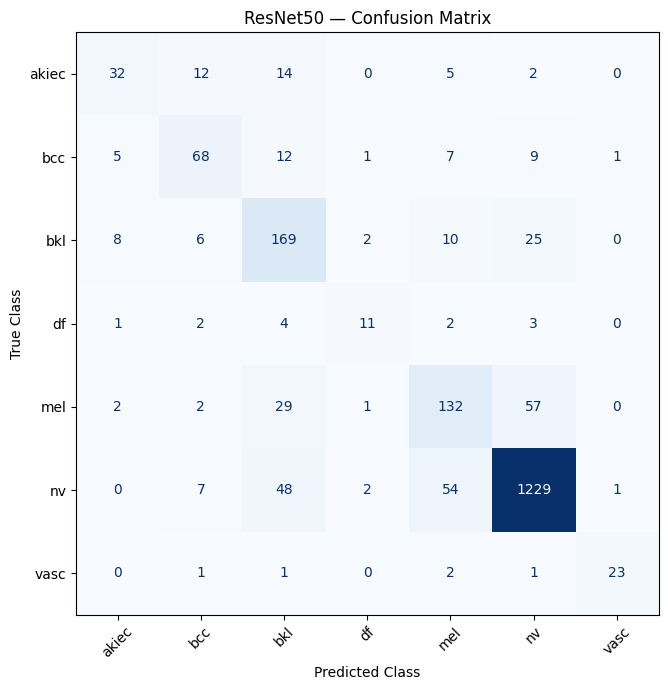

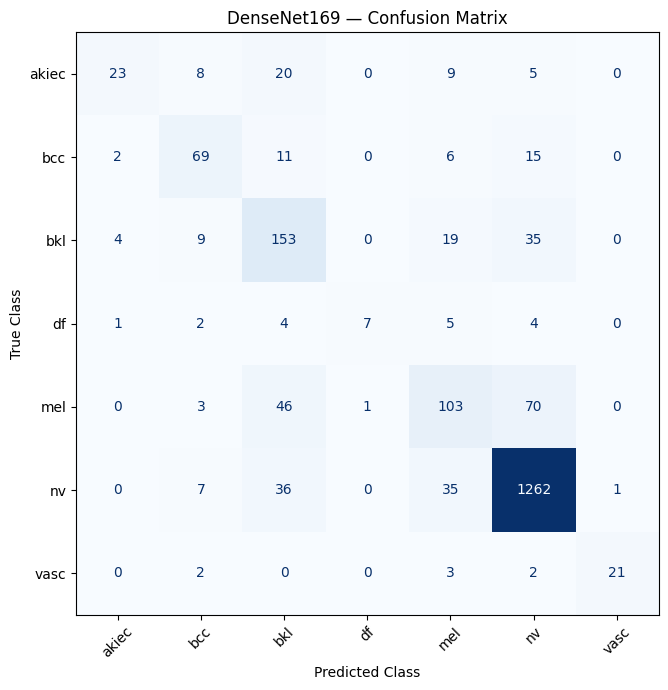

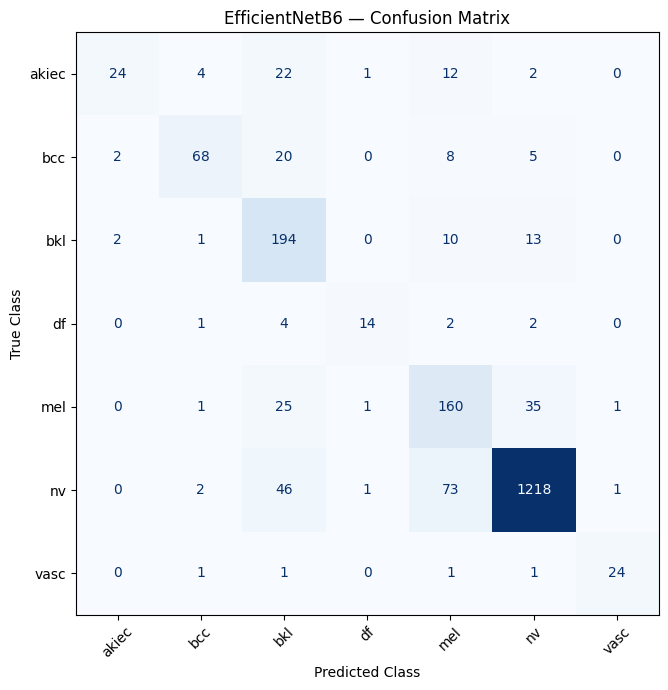

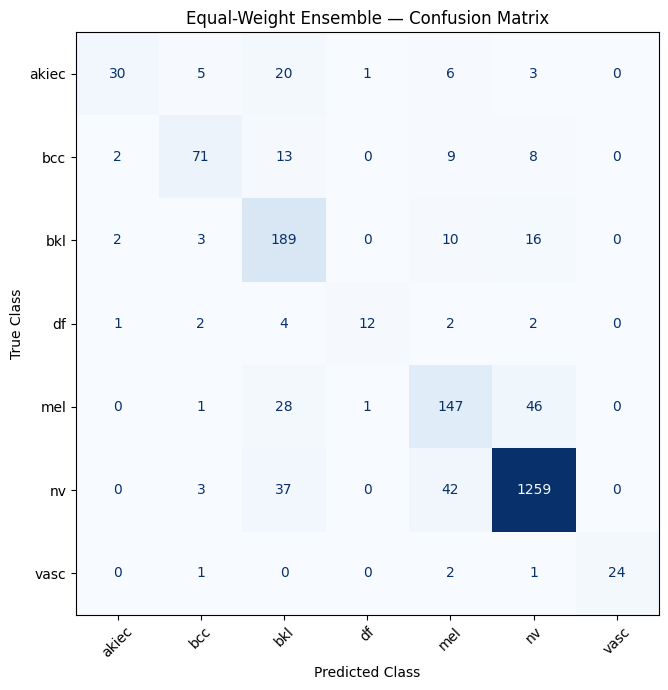

In [22]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

all_predictions = {
    "ResNet50": resnet_preds,
    "DenseNet169": densenet_preds,
    "EfficientNetB6": efficientnet_preds,
    "Equal-Weight Ensemble": ensemble_preds
}

for name, y_pred in all_predictions.items():
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=list(range(len(class_names)))
    )

    fig, ax = plt.subplots(figsize=(8, 7))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(f"{name} — Confusion Matrix")
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("True Class")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [24]:
import os
import pandas as pd
from sklearn.metrics import classification_report

OUTPUT_DIR = "/kaggle/working/ensemble_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

all_predictions = {
    "ResNet50": resnet_preds,
    "DenseNet169": densenet_preds,
    "EfficientNetB6": efficientnet_preds,
    "Equal-Weight Ensemble": ensemble_preds
}

# Generate classification reports
reports = {}

for name, y_pred in all_predictions.items():
    report = classification_report(
        y_true,
        y_pred,
        labels=list(range(len(class_names))),
        target_names=class_names,
        zero_division=0,
        digits=4
    )

    reports[name] = report

    print(f"\n{name} — Classification Report")
    print("-" * 50)
    print(report)

# Save comparison metrics
comparison_df.to_csv(
    os.path.join(OUTPUT_DIR, "model_comparison.csv"),
    index=False
)

# Save reports as text files
for name, report in reports.items():
    filename = name.lower().replace("-", "_").replace(" ", "_")
    report_path = os.path.join(
        OUTPUT_DIR,
        f"{filename}_classification_report.txt"
    )

    with open(report_path, "w") as file:
        file.write(report)

print("\nAll metrics and classification reports saved to:", OUTPUT_DIR)
print("\nSaved files:")

for filename in os.listdir(OUTPUT_DIR):
    print(filename)


ResNet50 — Classification Report
--------------------------------------------------
              precision    recall  f1-score   support

       akiec     0.6667    0.4923    0.5664        65
         bcc     0.6939    0.6602    0.6766       103
         bkl     0.6101    0.7682    0.6801       220
          df     0.6471    0.4783    0.5500        23
         mel     0.6226    0.5919    0.6069       223
          nv     0.9268    0.9165    0.9216      1341
        vasc     0.9200    0.8214    0.8679        28

    accuracy                         0.8308      2003
   macro avg     0.7267    0.6755    0.6956      2003
weighted avg     0.8345    0.8308    0.8309      2003


DenseNet169 — Classification Report
--------------------------------------------------
              precision    recall  f1-score   support

       akiec     0.7667    0.3538    0.4842        65
         bcc     0.6900    0.6699    0.6798       103
         bkl     0.5667    0.6955    0.6245       220
          df 

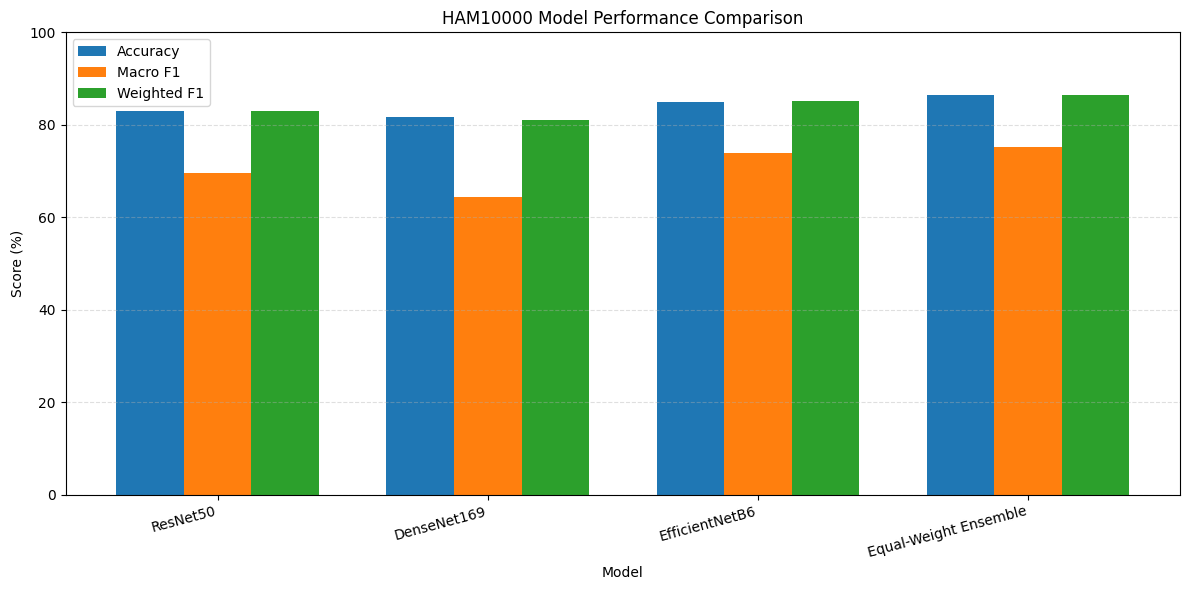

Comparison chart saved to: /kaggle/working/ensemble_results/model_comparison_chart.png


In [25]:
import os
import matplotlib.pyplot as plt
import numpy as np

OUTPUT_DIR = "/kaggle/working/ensemble_results"

metrics = ["Accuracy", "Macro F1", "Weighted F1"]
model_col = "Model"

plot_df = comparison_df.copy()

# Convert metric values to percentages if stored as decimals
for metric in metrics:
    if plot_df[metric].max() <= 1:
        plot_df[metric] = plot_df[metric] * 100

x = np.arange(len(plot_df[model_col]))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 6))

for i, metric in enumerate(metrics):
    ax.bar(
        x + (i - 1) * width,
        plot_df[metric],
        width,
        label=metric
    )

ax.set_title("HAM10000 Model Performance Comparison")
ax.set_xlabel("Model")
ax.set_ylabel("Score (%)")
ax.set_xticks(x)
ax.set_xticklabels(plot_df[model_col], rotation=15, ha="right")
ax.set_ylim(0, 100)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

chart_path = os.path.join(OUTPUT_DIR, "model_comparison_chart.png")
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Comparison chart saved to:", chart_path)

In [26]:
import os
import pandas as pd
import numpy as np

OUTPUT_DIR = "/kaggle/working/ensemble_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

predictions_df = pd.DataFrame({
    "image_id": test_df["image_id"].values,
    "filepath": test_df["filepath"].values,
    "true_class": [class_names[i] for i in y_true],

    "resnet50_prediction": [class_names[i] for i in resnet_preds],
    "resnet50_confidence": np.max(resnet_probs, axis=1),

    "densenet169_prediction": [class_names[i] for i in densenet_preds],
    "densenet169_confidence": np.max(densenet_probs, axis=1),

    "efficientnetb6_prediction": [class_names[i] for i in efficientnet_preds],
    "efficientnetb6_confidence": np.max(efficientnet_probs, axis=1),

    "ensemble_prediction": [class_names[i] for i in ensemble_preds],
    "ensemble_confidence": np.max(ensemble_probs, axis=1)
})

predictions_df["ensemble_correct"] = (
    predictions_df["true_class"] == predictions_df["ensemble_prediction"]
)

predictions_path = os.path.join(
    OUTPUT_DIR,
    "ensemble_test_predictions.csv"
)

predictions_df.to_csv(predictions_path, index=False)

print("Predictions saved to:", predictions_path)
print("Total test images:", len(predictions_df))
print("Correct ensemble predictions:", predictions_df["ensemble_correct"].sum())
print("Incorrect ensemble predictions:", (~predictions_df["ensemble_correct"]).sum())

display(predictions_df.head(10))

Predictions saved to: /kaggle/working/ensemble_results/ensemble_test_predictions.csv
Total test images: 2003
Correct ensemble predictions: 1732
Incorrect ensemble predictions: 271


,image_id,filepath,true_class,resnet50_prediction,resnet50_confidence,densenet169_prediction,densenet169_confidence,efficientnetb6_prediction,efficientnetb6_confidence,ensemble_prediction,ensemble_confidence,ensemble_correct
0,ISIC_0030038,/kaggle/input/datasets/kmader/skin-cancer-mnis...,nv,nv,0.734102,nv,0.893890,nv,0.950992,nv,0.859661,True
1,ISIC_0025442,/kaggle/input/datasets/kmader/skin-cancer-mnis...,nv,nv,0.977407,nv,0.907992,nv,0.604566,nv,0.829988,True
2,ISIC_0027204,/kaggle/input/datasets/kmader/skin-cancer-mnis...,mel,bkl,0.929814,bkl,0.727328,bkl,0.727559,bkl,0.794900,False
3,ISIC_0032165,/kaggle/input/datasets/kmader/skin-cancer-mnis...,nv,nv,0.896829,nv,0.982203,nv,0.999974,nv,0.959669,True
4,ISIC_0033185,/kaggle/input/datasets/kmader/skin-cancer-mnis...,bkl,mel,0.907443,bkl,0.591356,bkl,0.727612,mel,0.493354,False
5,ISIC_0025010,/kaggle/input/datasets/kmader/skin-cancer-mnis...,nv,nv,0.999920,nv,0.999996,nv,0.999571,nv,0.999829,True
6,ISIC_0032993,/kaggle/input/datasets/kmader/skin-cancer-mnis...,mel,mel,0.996083,mel,0.974157,mel,0.999992,mel,0.990077,True
7,ISIC_0032376,/kaggle/input/datasets/kmader/skin-cancer-mnis...,nv,nv,0.982346,bcc,0.818914,nv,0.999794,nv,0.720634,True
8,ISIC_0032106,/kaggle/input/datasets/kmader/skin-cancer-mnis...,nv,nv,0.999597,nv,0.999878,nv,0.999997,nv,0.999824,True
9,ISIC_0032137,/kaggle/input/datasets/kmader/skin-cancer-mnis...,nv,nv,0.999683,nv,0.999775,nv,0.999994,nv,0.999817,True


In [27]:
import pandas as pd
import numpy as np
import os

OUTPUT_DIR = "/kaggle/working/ensemble_results"

# Select incorrect ensemble predictions
misclassified_df = predictions_df[
    predictions_df["ensemble_correct"] == False
].copy()

# Count errors by actual class
error_summary = (
    misclassified_df.groupby("true_class")
    .size()
    .reindex(class_names, fill_value=0)
    .reset_index()
)

error_summary.columns = ["True Class", "Incorrect Predictions"]

# Calculate the total number of test samples in each class
class_totals = (
    predictions_df.groupby("true_class")
    .size()
    .reindex(class_names, fill_value=0)
)

error_summary["Total Test Images"] = error_summary["True Class"].map(class_totals)
error_summary["Error Rate (%)"] = (
    error_summary["Incorrect Predictions"] /
    error_summary["Total Test Images"].replace(0, np.nan) * 100
).round(2)

print("Ensemble errors by actual class:")
display(error_summary)

# Save error summary
error_summary.to_csv(
    os.path.join(OUTPUT_DIR, "ensemble_errors_by_class.csv"),
    index=False
)

# Show examples of misclassified images
print("\nExamples of incorrect ensemble predictions:")
display(
    misclassified_df[
        [
            "image_id",
            "true_class",
            "resnet50_prediction",
            "densenet169_prediction",
            "efficientnetb6_prediction",
            "ensemble_prediction",
            "ensemble_confidence"
        ]
    ].head(20)
)

# Save all misclassified examples
misclassified_df.to_csv(
    os.path.join(OUTPUT_DIR, "ensemble_misclassified_images.csv"),
    index=False
)

print("\nError summary and misclassified-image records saved.")

Ensemble errors by actual class:


,True Class,Incorrect Predictions,Total Test Images,Error Rate (%)
0,akiec,35,65,53.85
1,bcc,32,103,31.07
2,bkl,31,220,14.09
3,df,11,23,47.83
4,mel,76,223,34.08
5,nv,82,1341,6.11
6,vasc,4,28,14.29



Examples of incorrect ensemble predictions:


,image_id,true_class,resnet50_prediction,densenet169_prediction,efficientnetb6_prediction,ensemble_prediction,ensemble_confidence
2,ISIC_0027204,mel,bkl,bkl,bkl,bkl,0.794900
4,ISIC_0033185,bkl,mel,bkl,bkl,mel,0.493354
13,ISIC_0024554,mel,bkl,bkl,bkl,bkl,0.759859
15,ISIC_0033222,nv,mel,mel,mel,mel,0.703836
22,ISIC_0031550,mel,nv,nv,nv,nv,0.832296
24,ISIC_0032046,mel,nv,nv,mel,nv,0.370087
25,ISIC_0034203,nv,bcc,bcc,nv,bcc,0.586096
34,ISIC_0024323,mel,bkl,bkl,bkl,bkl,0.679577
39,ISIC_0032015,nv,nv,nv,mel,mel,0.539129
41,ISIC_0027859,bkl,akiec,akiec,bkl,akiec,0.482327



Error summary and misclassified-image records saved.


,Class,Precision,Recall,F1-score
0,akiec,0.8571,0.4615,0.6000
1,bcc,0.8256,0.6893,0.7513
2,bkl,0.6495,0.8591,0.7397
3,df,0.8571,0.5217,0.6486
4,mel,0.6743,0.6592,0.6667
5,nv,0.9431,0.9389,0.9410
6,vasc,1.0000,0.8571,0.9231


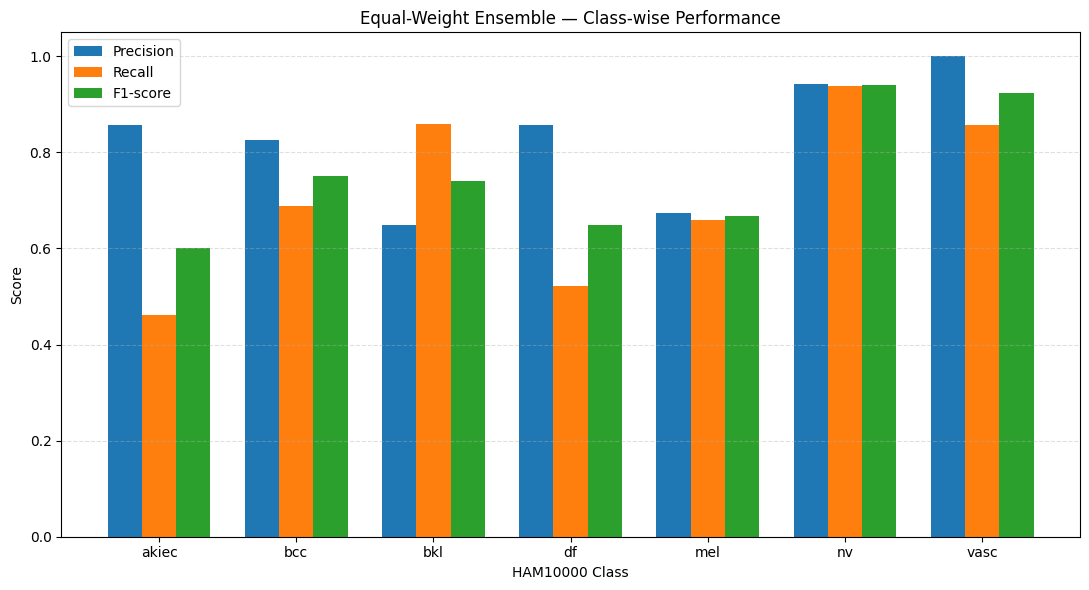

Class-wise metrics and chart saved.
Chart: /kaggle/working/ensemble_results/ensemble_classwise_performance.png


In [28]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report

OUTPUT_DIR = "/kaggle/working/ensemble_results"

# Generate class-wise metrics for the ensemble
report_dict = classification_report(
    y_true,
    ensemble_preds,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

class_metrics = pd.DataFrame([
    {
        "Class": class_name,
        "Precision": report_dict[class_name]["precision"],
        "Recall": report_dict[class_name]["recall"],
        "F1-score": report_dict[class_name]["f1-score"]
    }
    for class_name in class_names
])

display(class_metrics.round(4))

# Save class-wise metrics
class_metrics.to_csv(
    os.path.join(OUTPUT_DIR, "ensemble_classwise_metrics.csv"),
    index=False
)

# Plot the class-wise metrics
x = np.arange(len(class_names))
width = 0.25

fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(x - width, class_metrics["Precision"], width, label="Precision")
ax.bar(x, class_metrics["Recall"], width, label="Recall")
ax.bar(x + width, class_metrics["F1-score"], width, label="F1-score")

ax.set_title("Equal-Weight Ensemble — Class-wise Performance")
ax.set_xlabel("HAM10000 Class")
ax.set_ylabel("Score")
ax.set_xticks(x)
ax.set_xticklabels(class_names)
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

chart_path = os.path.join(
    OUTPUT_DIR,
    "ensemble_classwise_performance.png"
)

plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Class-wise metrics and chart saved.")
print("Chart:", chart_path)

In [32]:
import os
import zipfile

OUTPUT_DIR = "/kaggle/working/ensemble_results"
ZIP_PATH = "/kaggle/working/ensemble_results.zip"

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk(OUTPUT_DIR):
        for filename in files:
            file_path = os.path.join(root, filename)
            arcname = os.path.relpath(file_path, OUTPUT_DIR)
            zipf.write(file_path, arcname)

print("Ensemble results packaged successfully.")
print("ZIP file:", ZIP_PATH)
print("Files included:")

with zipfile.ZipFile(ZIP_PATH, "r") as zipf:
    for filename in zipf.namelist():
        print(filename)

Ensemble results packaged successfully.
ZIP file: /kaggle/working/ensemble_results.zip
Files included:
model_comparison.csv
ensemble_misclassified_images.csv
ensemble_classwise_metrics.csv
tuned_ensemble_test_predictions.csv
ensemble_test_predictions.csv
tuned_ensemble_classification_report.txt
tuned_ensemble_config.json
equal_weight_ensemble_classification_report.txt
model_comparison_chart.png
ensemble_classwise_performance.png
densenet169_classification_report.txt
efficientnetb6_classification_report.txt
resnet50_classification_report.txt
ensemble_errors_by_class.csv


In [30]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Prepare validation data
val_paths = val_df["filepath"].values
val_labels = val_df["label"].values.astype(np.int32)

resnet_val_ds = make_test_dataset(
    val_paths, val_labels, (224, 224), preprocess_fn=None
)

densenet_val_ds = make_test_dataset(
    val_paths, val_labels, (224, 224), preprocess_fn=densenet_preprocess
)

efficientnet_val_ds = make_test_dataset(
    val_paths, val_labels, (528, 528), preprocess_fn=None
)

# Get validation probabilities with the correct preprocessing
print("Predicting validation set...")

resnet_val_probs = resnet_model.predict(resnet_val_ds, verbose=1)
densenet_val_probs = densenet_model.predict(densenet_val_ds, verbose=1)
efficientnet_val_probs = efficientnet_model.predict(efficientnet_val_ds, verbose=1)

# Search weights in increments of 0.05.
# The three weights always sum to 1.
weight_values = np.arange(0, 1.001, 0.05)
weight_values = np.round(weight_values, 2)

weight_results = []

for w_resnet in weight_values:
    for w_densenet in weight_values:
        w_efficientnet = round(1.0 - w_resnet - w_densenet, 2)

        if w_efficientnet < 0 or w_efficientnet > 1:
            continue

        val_ensemble_probs = (
            w_resnet * resnet_val_probs
            + w_densenet * densenet_val_probs
            + w_efficientnet * efficientnet_val_probs
        )

        val_ensemble_preds = np.argmax(val_ensemble_probs, axis=1)

        val_accuracy = accuracy_score(val_labels, val_ensemble_preds)
        val_macro_f1 = f1_score(
            val_labels,
            val_ensemble_preds,
            average="macro",
            zero_division=0
        )

        weight_results.append({
            "ResNet50 Weight": w_resnet,
            "DenseNet169 Weight": w_densenet,
            "EfficientNetB6 Weight": w_efficientnet,
            "Validation Accuracy": val_accuracy,
            "Validation Macro F1": val_macro_f1
        })

weight_results_df = pd.DataFrame(weight_results)

# Select weights by validation accuracy.
# If accuracy ties, prefer the higher validation macro F1.
weight_results_df = weight_results_df.sort_values(
    by=["Validation Accuracy", "Validation Macro F1"],
    ascending=False
).reset_index(drop=True)

print("\nTop 10 weight combinations on validation data:")
display(weight_results_df.head(10))

best_weights = weight_results_df.iloc[0]

w_resnet = float(best_weights["ResNet50 Weight"])
w_densenet = float(best_weights["DenseNet169 Weight"])
w_efficientnet = float(best_weights["EfficientNetB6 Weight"])

print("\nSelected weights:")
print(f"ResNet50:      {w_resnet:.2f}")
print(f"DenseNet169:   {w_densenet:.2f}")
print(f"EfficientNetB6:{w_efficientnet: .2f}")
print(f"Validation accuracy: {best_weights['Validation Accuracy']:.4%}")
print(f"Validation macro F1: {best_weights['Validation Macro F1']:.4f}")

# Apply the selected weights to the held-out test predictions
tuned_ensemble_probs = (
    w_resnet * resnet_probs
    + w_densenet * densenet_probs
    + w_efficientnet * efficientnet_probs
)

tuned_ensemble_preds = np.argmax(tuned_ensemble_probs, axis=1)

tuned_test_accuracy = accuracy_score(y_true, tuned_ensemble_preds)
tuned_test_macro_f1 = f1_score(
    y_true,
    tuned_ensemble_preds,
    average="macro",
    zero_division=0
)
tuned_test_weighted_f1 = f1_score(
    y_true,
    tuned_ensemble_preds,
    average="weighted",
    zero_division=0
)

print("\nTuned ensemble — test set results")
print(f"Accuracy:        {tuned_test_accuracy:.4%}")
print(f"Macro F1-score:  {tuned_test_macro_f1:.4f}")
print(f"Weighted F1:     {tuned_test_weighted_f1:.4f}")

print("\nClassification report:")
print(classification_report(
    y_true,
    tuned_ensemble_preds,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0,
    digits=4
))

Predicting validation set...
32/32 ━━━━━━━━━━━━━━━━━━━━ 5s 150ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 19s 621ms/step
31/32 ━━━━━━━━━━━━━━━━━━━━ 0s 924ms/step

2026-09-23 06:21:42.038633: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-23 06:21:42.259854: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-23 06:21:42.754220: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-23 06:21:42.997572: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-23 06:21:44.688870: E external/local_xla/xla/stream_

32/32 ━━━━━━━━━━━━━━━━━━━━ 56s 2s/step 

Top 10 weight combinations on validation data:


,ResNet50 Weight,DenseNet169 Weight,EfficientNetB6 Weight,Validation Accuracy,Validation Macro F1
0,0.35,0.30,0.35,0.880240,0.785908
1,0.35,0.25,0.40,0.879242,0.791243
2,0.40,0.30,0.30,0.879242,0.787442
3,0.35,0.35,0.30,0.879242,0.786158
4,0.50,0.15,0.35,0.879242,0.779701
5,0.40,0.25,0.35,0.878244,0.785483
6,0.45,0.30,0.25,0.878244,0.779333
7,0.55,0.10,0.35,0.878244,0.779127
8,0.25,0.45,0.30,0.878244,0.769809
9,0.40,0.20,0.40,0.877246,0.789448



Selected weights:
ResNet50:      0.35
DenseNet169:   0.30
EfficientNetB6: 0.35
Validation accuracy: 88.0240%
Validation macro F1: 0.7859

Tuned ensemble — test set results
Accuracy:        86.6201%
Macro F1-score:  0.7592
Weighted F1:     0.8656

Classification report:
              precision    recall  f1-score   support

       akiec     0.8571    0.4615    0.6000        65
         bcc     0.8409    0.7184    0.7749       103
         bkl     0.6473    0.8591    0.7383       220
          df     0.8571    0.5217    0.6486        23
         mel     0.6774    0.6592    0.6682       223
          nv     0.9444    0.9381    0.9413      1341
        vasc     1.0000    0.8929    0.9434        28

    accuracy                         0.8662      2003
   macro avg     0.8320    0.7216    0.7592      2003
weighted avg     0.8737    0.8662    0.8656      2003



In [31]:
import os
import json
import pandas as pd
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

OUTPUT_DIR = "/kaggle/working/ensemble_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Calculate tuned ensemble metrics
tuned_metrics = {
    "Model": "Tuned Weighted Ensemble",
    "Accuracy": accuracy_score(y_true, tuned_ensemble_preds),
    "Macro Precision": precision_score(
        y_true, tuned_ensemble_preds, average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_true, tuned_ensemble_preds, average="macro", zero_division=0
    ),
    "Macro F1": f1_score(
        y_true, tuned_ensemble_preds, average="macro", zero_division=0
    ),
    "Weighted F1": f1_score(
        y_true, tuned_ensemble_preds, average="weighted", zero_division=0
    )
}

# Add tuned ensemble to the existing comparison table
tuned_row = pd.DataFrame([tuned_metrics])
comparison_df = pd.concat(
    [comparison_df, tuned_row],
    ignore_index=True
)

comparison_df.to_csv(
    os.path.join(OUTPUT_DIR, "model_comparison.csv"),
    index=False
)

# Save the selected weights and validation metrics
tuned_config = {
    "method": "Validation-selected weighted soft voting",
    "weights": {
        "ResNet50": w_resnet,
        "DenseNet169": w_densenet,
        "EfficientNetB6": w_efficientnet
    },
    "validation_accuracy": float(best_weights["Validation Accuracy"]),
    "validation_macro_f1": float(best_weights["Validation Macro F1"]),
    "test_metrics": {
        key: float(value)
        for key, value in tuned_metrics.items()
        if key != "Model"
    }
}

config_path = os.path.join(OUTPUT_DIR, "tuned_ensemble_config.json")

with open(config_path, "w", encoding="utf-8") as file:
    json.dump(tuned_config, file, indent=4)

# Save the tuned ensemble classification report
tuned_report = classification_report(
    y_true,
    tuned_ensemble_preds,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0,
    digits=4
)

with open(
    os.path.join(OUTPUT_DIR, "tuned_ensemble_classification_report.txt"),
    "w",
    encoding="utf-8"
) as file:
    file.write(tuned_report)

# Save predictions from the tuned ensemble
tuned_predictions_df = pd.DataFrame({
    "image_id": test_df["image_id"].values,
    "true_class": [class_names[i] for i in y_true],
    "tuned_ensemble_prediction": [
        class_names[i] for i in tuned_ensemble_preds
    ],
    "tuned_ensemble_confidence": np.max(tuned_ensemble_probs, axis=1)
})

tuned_predictions_df["correct"] = (
    tuned_predictions_df["true_class"]
    == tuned_predictions_df["tuned_ensemble_prediction"]
)

tuned_predictions_df.to_csv(
    os.path.join(OUTPUT_DIR, "tuned_ensemble_test_predictions.csv"),
    index=False
)

print("Tuned ensemble files saved.")
print("\nUpdated model comparison:")
display(comparison_df)

print("\nSaved files:")
for filename in sorted(os.listdir(OUTPUT_DIR)):
    print(filename)

Tuned ensemble files saved.

Updated model comparison:


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,ResNet50,0.830754,0.726743,0.675540,0.695646,0.830916
1,DenseNet169,0.817773,0.761580,0.596646,0.644925,0.811171
2,EfficientNetB6,0.849725,0.807627,0.714693,0.738708,0.852004
3,Equal-Weight Ensemble,0.864703,0.829534,0.712411,0.752914,0.863894
4,Tuned Weighted Ensemble,0.866201,0.832046,0.721567,0.759235,0.865605



Saved files:
densenet169_classification_report.txt
efficientnetb6_classification_report.txt
ensemble_classwise_metrics.csv
ensemble_classwise_performance.png
ensemble_errors_by_class.csv
ensemble_misclassified_images.csv
ensemble_test_predictions.csv
equal_weight_ensemble_classification_report.txt
model_comparison.csv
model_comparison_chart.png
resnet50_classification_report.txt
tuned_ensemble_classification_report.txt
tuned_ensemble_config.json
tuned_ensemble_test_predictions.csv


In [36]:
import os
import zipfile

OUTPUT_DIR = "/kaggle/working/ensemble_results"
ZIP_PATH = "/kaggle/working/ensemble_results.zip"

# Recreate the archive with the latest result files
with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk(OUTPUT_DIR):
        for filename in files:
            file_path = os.path.join(root, filename)
            arcname = os.path.relpath(file_path, OUTPUT_DIR)
            zipf.write(file_path, arcname)

print("Updated ZIP archive created:", ZIP_PATH)

print("\nFiles included:")
with zipfile.ZipFile(ZIP_PATH, "r") as zipf:
    for filename in sorted(zipf.namelist()):
        print(filename)

print("\nArchive size: {:.2f} MB".format(os.path.getsize(ZIP_PATH) / (1024 * 1024)))

Updated ZIP archive created: /kaggle/working/ensemble_results.zip

Files included:
densenet169_classification_report.txt
efficientnetb6_classification_report.txt
ensemble_classwise_metrics.csv
ensemble_classwise_performance.png
ensemble_errors_by_class.csv
ensemble_misclassified_images.csv
ensemble_test_predictions.csv
equal_weight_ensemble_classification_report.txt
final_ensemble_comparison.csv
model_comparison.csv
model_comparison_chart.png
resnet50_classification_report.txt
tuned_ensemble_classification_report.txt
tuned_ensemble_config.json
tuned_ensemble_confusion_matrix.png
tuned_ensemble_test_predictions.csv

Archive size: 0.39 MB


In [34]:
import os
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

OUTPUT_DIR = "/kaggle/working/ensemble_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

final_summary = pd.DataFrame([
    {
        "Model": "Equal-Weight Ensemble",
        "Accuracy (%)": accuracy_score(y_true, ensemble_preds) * 100,
        "Macro Precision": precision_score(
            y_true, ensemble_preds, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, ensemble_preds, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_true, ensemble_preds, average="macro", zero_division=0
        ),
        "Weighted F1": f1_score(
            y_true, ensemble_preds, average="weighted", zero_division=0
        )
    },
    {
        "Model": "Tuned Weighted Ensemble",
        "Accuracy (%)": accuracy_score(y_true, tuned_ensemble_preds) * 100,
        "Macro Precision": precision_score(
            y_true, tuned_ensemble_preds, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, tuned_ensemble_preds, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_true, tuned_ensemble_preds, average="macro", zero_division=0
        ),
        "Weighted F1": f1_score(
            y_true, tuned_ensemble_preds, average="weighted", zero_division=0
        )
    }
])

display(final_summary.round(4))

summary_path = os.path.join(OUTPUT_DIR, "final_ensemble_comparison.csv")
final_summary.to_csv(summary_path, index=False)

print("Final ensemble comparison saved to:", summary_path)

,Model,Accuracy (%),Macro Precision,Macro Recall,Macro F1,Weighted F1
0,Equal-Weight Ensemble,86.4703,0.8295,0.7124,0.7529,0.8639
1,Tuned Weighted Ensemble,86.6201,0.8320,0.7216,0.7592,0.8656


Final ensemble comparison saved to: /kaggle/working/ensemble_results/final_ensemble_comparison.csv


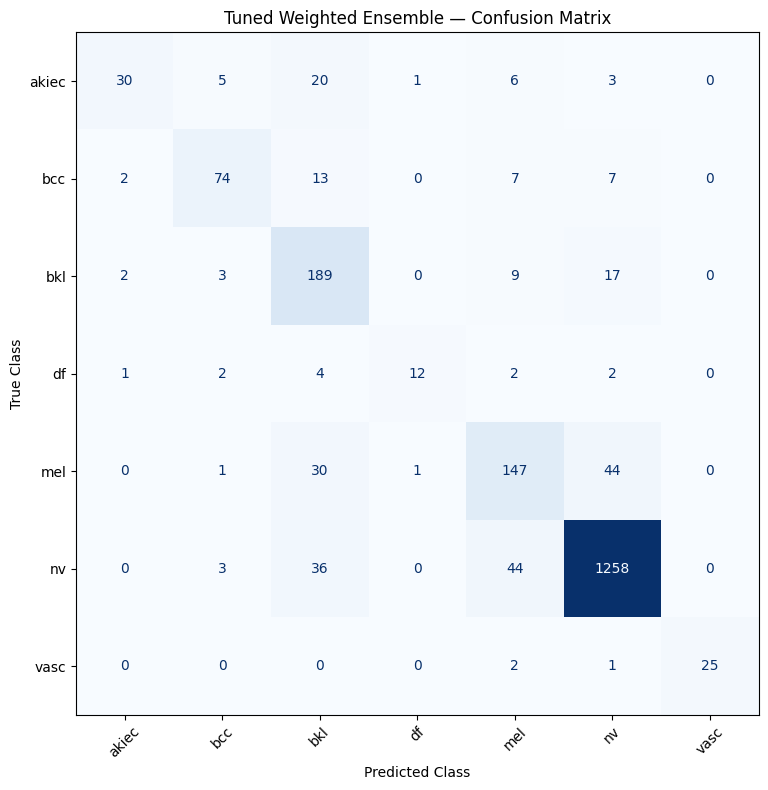

Tuned ensemble confusion matrix saved to: /kaggle/working/ensemble_results/tuned_ensemble_confusion_matrix.png


In [35]:
import os
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

OUTPUT_DIR = "/kaggle/working/ensemble_results"

cm = confusion_matrix(
    y_true,
    tuned_ensemble_preds,
    labels=list(range(len(class_names)))
)

fig, ax = plt.subplots(figsize=(9, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("Tuned Weighted Ensemble — Confusion Matrix")
ax.set_xlabel("Predicted Class")
ax.set_ylabel("True Class")

plt.xticks(rotation=45)
plt.tight_layout()

cm_path = os.path.join(
    OUTPUT_DIR,
    "tuned_ensemble_confusion_matrix.png"
)

plt.savefig(cm_path, dpi=300, bbox_inches="tight")
plt.show()

print("Tuned ensemble confusion matrix saved to:", cm_path)

**GRAD-CAM**

In [43]:
import tensorflow as tf

def inspect_model_structure(model, indent=0):
    for layer in model.layers:
        print(
            " " * indent
            + f"{layer.name} | {type(layer).__name__} | "
            + f"output shape: {getattr(layer, 'output_shape', 'N/A')}"
        )

        if isinstance(layer, tf.keras.Model):
            inspect_model_structure(layer, indent + 4)


print("\n========== RESNET50 ==========")
inspect_model_structure(resnet_model)

print("\n========== DENSENET169 ==========")
inspect_model_structure(densenet_model)

print("\n========== EFFICIENTNETB6 ==========")
inspect_model_structure(efficientnet_model)


========== RESNET50 ==========
input_image | InputLayer | output shape: N/A
data_augmentation | Sequential | output shape: (None, 224, 224, 3)
    random_flip_2 | RandomFlip | output shape: N/A
    random_rotation_2 | RandomRotation | output shape: N/A
    random_zoom_2 | RandomZoom | output shape: N/A
    random_translation_2 | RandomTranslation | output shape: N/A
    random_contrast_2 | RandomContrast | output shape: N/A
preprocess | Lambda | output shape: N/A
resnet50 | Functional | output shape: (None, 7, 7, 2048)
    input_layer_14 | InputLayer | output shape: N/A
    conv1_pad | ZeroPadding2D | output shape: N/A
    conv1_conv | Conv2D | output shape: N/A
    conv1_bn | BatchNormalization | output shape: N/A
    conv1_relu | Activation | output shape: N/A
    pool1_pad | ZeroPadding2D | output shape: N/A
    pool1_pool | MaxPooling2D | output shape: N/A
    conv2_block1_1_conv | Conv2D | output shape: N/A
    conv2_block1_1_bn | BatchNormalization | output shape: N/A
    conv2_

In [44]:
def list_conv_layers(model, prefix=""):
    for layer in model.layers:
        current_name = f"{prefix}/{layer.name}"

        if isinstance(layer, tf.keras.layers.Conv2D):
            print(current_name)

        if isinstance(layer, tf.keras.Model):
            list_conv_layers(layer, current_name)


print("\nResNet50 convolutional layers:")
list_conv_layers(resnet_model)

print("\nDenseNet169 convolutional layers:")
list_conv_layers(densenet_model)

print("\nEfficientNetB6 convolutional layers:")
list_conv_layers(efficientnet_model)


ResNet50 convolutional layers:
/resnet50/conv1_conv
/resnet50/conv2_block1_1_conv
/resnet50/conv2_block1_2_conv
/resnet50/conv2_block1_0_conv
/resnet50/conv2_block1_3_conv
/resnet50/conv2_block2_1_conv
/resnet50/conv2_block2_2_conv
/resnet50/conv2_block2_3_conv
/resnet50/conv2_block3_1_conv
/resnet50/conv2_block3_2_conv
/resnet50/conv2_block3_3_conv
/resnet50/conv3_block1_1_conv
/resnet50/conv3_block1_2_conv
/resnet50/conv3_block1_0_conv
/resnet50/conv3_block1_3_conv
/resnet50/conv3_block2_1_conv
/resnet50/conv3_block2_2_conv
/resnet50/conv3_block2_3_conv
/resnet50/conv3_block3_1_conv
/resnet50/conv3_block3_2_conv
/resnet50/conv3_block3_3_conv
/resnet50/conv3_block4_1_conv
/resnet50/conv3_block4_2_conv
/resnet50/conv3_block4_3_conv
/resnet50/conv4_block1_1_conv
/resnet50/conv4_block1_2_conv
/resnet50/conv4_block1_0_conv
/resnet50/conv4_block1_3_conv
/resnet50/conv4_block2_1_conv
/resnet50/conv4_block2_2_conv
/resnet50/conv4_block2_3_conv
/resnet50/conv4_block3_1_conv
/resnet50/conv4_b

In [45]:
for model_name, model in [
    ("ResNet50", resnet_model),
    ("DenseNet169", densenet_model),
    ("EfficientNetB6", efficientnet_model)
]:
    print(f"\n{model_name} outer model layers:")

    for i, layer in enumerate(model.layers):
        print(
            i,
            layer.name,
            type(layer).__name__,
            getattr(layer, "output_shape", "shape unavailable")
        )


ResNet50 outer model layers:
0 input_image InputLayer shape unavailable
1 data_augmentation Sequential (None, 224, 224, 3)
2 preprocess Lambda shape unavailable
3 resnet50 Functional (None, 7, 7, 2048)
4 global_average_pooling2d_7 GlobalAveragePooling2D shape unavailable
5 dropout_14 Dropout shape unavailable
6 dense_8 Dense shape unavailable
7 dropout_15 Dropout shape unavailable
8 output Dense shape unavailable

DenseNet169 outer model layers:
0 densenet169 Functional (None, 7, 7, 1664)
1 global_average_pooling2d_2 GlobalAveragePooling2D shape unavailable
2 dropout_4 Dropout shape unavailable
3 dense_4 Dense shape unavailable
4 dropout_5 Dropout shape unavailable
5 dense_5 Dense shape unavailable

EfficientNetB6 outer model layers:
0 input_layer_1 InputLayer shape unavailable
1 efficientnetb6 Functional (None, 17, 17, 2304)
2 global_average_pooling2d GlobalAveragePooling2D shape unavailable
3 dropout Dropout shape unavailable
4 dense Dense shape unavailable


In [46]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def find_last_conv_layer(backbone):
    conv_layers = [
        layer for layer in backbone.layers
        if isinstance(layer, tf.keras.layers.Conv2D)
    ]

    if conv_layers:
        return conv_layers[-1]

    for layer in reversed(backbone.layers):
        if isinstance(layer, tf.keras.Model):
            result = find_last_conv_layer(layer)
            if result is not None:
                return result

    return None


def make_gradcam_model(model, backbone_name):
    backbone = model.get_layer(backbone_name)
    last_conv = find_last_conv_layer(backbone)

    if last_conv is None:
        raise ValueError(f"No Conv2D layer found in {backbone_name}")

    print(f"Using convolutional layer: {last_conv.name}")

    # Build a feature extractor that returns the final convolutional features.
    feature_model = tf.keras.Model(
        inputs=backbone.inputs,
        outputs=last_conv.output
    )

    return backbone, feature_model


def gradcam_for_model(model, backbone_name, image_tensor, class_index):
    backbone, feature_model = make_gradcam_model(model, backbone_name)

    # Calculate the feature maps and obtain the gradient of the target score.
    with tf.GradientTape() as tape:
        feature_maps = feature_model(image_tensor, training=False)
        tape.watch(feature_maps)

        # Pass feature maps through the remaining backbone layers is not
        # sufficient for every architecture, so use the model's nested backbone
        # output to obtain the prediction score separately.
        backbone_output = backbone(image_tensor, training=False)

        x = backbone_output
        backbone_position = model.layers.index(backbone)

        for layer in model.layers[backbone_position + 1:]:
            x = layer(x, training=False)

        score = x[:, class_index]

    grads = tape.gradient(score, feature_maps)

    if grads is None:
        raise RuntimeError(
            "Gradient is disconnected. The backbone and feature extractor "
            "must share the same computation graph for this model."
        )

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    feature_maps = feature_maps[0]

    heatmap = tf.reduce_sum(feature_maps * pooled_grads, axis=-1)
    heatmap = tf.maximum(heatmap, 0)

    max_value = tf.reduce_max(heatmap)
    heatmap = heatmap / (max_value + tf.keras.backend.epsilon())

    return heatmap.numpy()


print("Grad-CAM setup cell executed.")

Grad-CAM setup cell executed.


In [48]:
import tensorflow as tf

model_backbones = [
    ("ResNet50", resnet_model, "resnet50"),
    ("DenseNet169", densenet_model, "densenet169"),
    ("EfficientNetB6", efficientnet_model, "efficientnetb6")
]

for model_name, model, backbone_name in model_backbones:
    backbone = model.get_layer(backbone_name)

    print(f"\n{model_name}")
    print("Backbone input:", backbone.input)
    print("Backbone output:", backbone.output)

    conv_layer = find_last_conv_layer(backbone)

    if conv_layer is not None:
        print("Last Conv2D layer:", conv_layer.name)
        print("Layer output:", conv_layer.output)
    else:
        print("No Conv2D layer found.")


ResNet50
Backbone input: <KerasTensor shape=(None, 224, 224, 3), dtype=float32, sparse=False, ragged=False, name=input_layer_14>
Backbone output: <KerasTensor shape=(None, 7, 7, 2048), dtype=float32, sparse=False, ragged=False, name=keras_tensor_408>
Last Conv2D layer: conv5_block3_3_conv
Layer output: <KerasTensor shape=(None, 7, 7, 2048), dtype=float32, sparse=False, ragged=False, name=keras_tensor_401>

DenseNet169
Backbone input: <KerasTensor shape=(None, 224, 224, 3), dtype=float32, sparse=False, ragged=False, name=input_layer_4>
Backbone output: <KerasTensor shape=(None, 7, 7, 1664), dtype=float32, sparse=False, ragged=False, name=keras_tensor_1696>
Last Conv2D layer: conv5_block32_2_conv
Layer output: <KerasTensor shape=(None, 7, 7, 32), dtype=float32, sparse=False, ragged=False, name=keras_tensor_1689>

EfficientNetB6
Backbone input: <KerasTensor shape=(None, 528, 528, 3), dtype=float32, sparse=False, ragged=False, name=input_layer>
Backbone output: <KerasTensor shape=(None, 1

In [51]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def build_gradcam_model(model, backbone_name):
    backbone = model.get_layer(backbone_name)
    last_conv = find_last_conv_layer(backbone)

    if last_conv is None:
        raise ValueError(f"No Conv2D layer found in {backbone_name}")

    # Construct the feature extractor from the backbone's own graph.
    feature_extractor = tf.keras.Model(
        inputs=backbone.inputs,
        outputs=last_conv.output
    )

    # Identify the backbone's output tensor and connect it to the classifier head.
    feature_input = tf.keras.Input(shape=backbone.output.shape[1:])
    x = feature_input

    backbone_index = model.layers.index(backbone)

    for layer in model.layers[backbone_index + 1:]:
        x = layer(x)

    classifier = tf.keras.Model(feature_input, x)

    return feature_extractor, classifier


def generate_gradcam(model, backbone_name, image_tensor):
    feature_extractor, classifier = build_gradcam_model(
        model, backbone_name
    )

    with tf.GradientTape() as tape:
        conv_features = feature_extractor(image_tensor, training=False)
        tape.watch(conv_features)

        predictions = classifier(conv_features, training=False)
        predicted_class = tf.argmax(predictions[0])
        target_score = predictions[:, predicted_class]

    gradients = tape.gradient(target_score, conv_features)

    if gradients is None:
        raise RuntimeError(
            f"Gradients are disconnected for {backbone_name}."
        )

    weights = tf.reduce_mean(gradients, axis=(0, 1, 2))
    conv_features = conv_features[0]

    heatmap = tf.reduce_sum(conv_features * weights, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    heatmap /= tf.reduce_max(heatmap) + tf.keras.backend.epsilon()

    return heatmap.numpy(), int(predicted_class.numpy())


print("Updated Grad-CAM functions defined.")

Updated Grad-CAM functions defined.


In [52]:
gradcam_models = [
    ("ResNet50", resnet_model, "resnet50", resnet_image),
    ("DenseNet169", densenet_model, "densenet169", densenet_image),
    ("EfficientNetB6", efficientnet_model, "efficientnetb6", efficientnet_image)
]

gradcam_results = {}
gradcam_errors = {}

for name, model, backbone_name, image_tensor in gradcam_models:
    print(f"\nTesting Grad-CAM for {name}...")

    try:
        heatmap, predicted_class = generate_gradcam(
            model,
            backbone_name,
            image_tensor
        )

        gradcam_results[name] = (heatmap, predicted_class)
        print(f"Success. Predicted class: {class_names[predicted_class]}")

    except Exception as error:
        gradcam_errors[name] = str(error)
        print(f"Failed: {type(error).__name__}: {error}")

print("\nGrad-CAM diagnostic summary")
print("Successful models:", list(gradcam_results.keys()))
print("Failed models:", list(gradcam_errors.keys()))


Testing Grad-CAM for ResNet50...
Success. Predicted class: bkl

Testing Grad-CAM for DenseNet169...
Failed: ValueError: Input 0 with name 'input_layer_2' of layer 'functional_29' is incompatible with the layer: expected shape=(None, 7, 7, 1664), found shape=(1, 7, 7, 32)

Testing Grad-CAM for EfficientNetB6...
Success. Predicted class: nv

Grad-CAM diagnostic summary
Successful models: ['ResNet50', 'EfficientNetB6']
Failed models: ['DenseNet169']


In [53]:
densenet_backbone = densenet_model.get_layer("densenet169")
densenet_conv = find_last_conv_layer(densenet_backbone)

print("Selected convolutional layer:", densenet_conv.name)

conv_index = next(
    i for i, layer in enumerate(densenet_backbone.layers)
    if layer.name == densenet_conv.name
)

print("\nLayers following the selected convolution:")
for i, layer in enumerate(
    densenet_backbone.layers[conv_index + 1:conv_index + 8],
    start=conv_index + 1
):
    print(i, layer.name, type(layer).__name__)

print("\nDenseNet backbone output shape:", densenet_backbone.output.shape)

Selected convolutional layer: conv5_block32_2_conv

Layers following the selected convolution:
592 conv5_block32_concat Concatenate
593 bn BatchNormalization
594 relu Activation

DenseNet backbone output shape: (None, 7, 7, 1664)


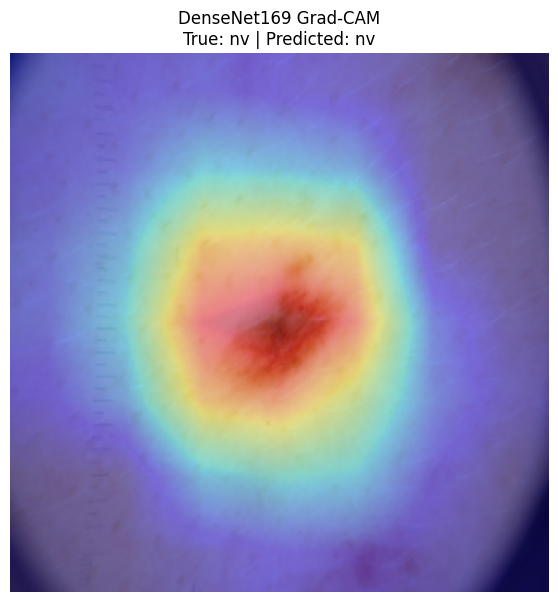

In [54]:
def generate_densenet_gradcam(model, image_tensor):
    backbone = model.get_layer("densenet169")

    # Use the final backbone output so the DenseNet concatenation is preserved.
    feature_extractor = tf.keras.Model(
        inputs=backbone.inputs,
        outputs=backbone.output
    )

    with tf.GradientTape() as tape:
        features = feature_extractor(image_tensor, training=False)
        tape.watch(features)

        # Pass features through the DenseNet classification head.
        x = features

        backbone_index = model.layers.index(backbone)
        for layer in model.layers[backbone_index + 1:]:
            x = layer(x, training=False)

        predictions = x
        predicted_class = tf.argmax(predictions[0])
        target_score = predictions[:, predicted_class]

    gradients = tape.gradient(target_score, features)

    if gradients is None:
        raise RuntimeError("DenseNet169 Grad-CAM gradients are disconnected.")

    weights = tf.reduce_mean(gradients, axis=(0, 1, 2))
    feature_map = features[0]

    heatmap = tf.reduce_sum(feature_map * weights, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    heatmap /= tf.reduce_max(heatmap) + tf.keras.backend.epsilon()

    return heatmap.numpy(), int(predicted_class.numpy())


# Generate DenseNet169 Grad-CAM
densenet_heatmap, densenet_predicted_class = generate_densenet_gradcam(
    densenet_model,
    densenet_image
)

# Resize heatmap to match the displayed image
densenet_heatmap_resized = tf.image.resize(
    densenet_heatmap[..., np.newaxis],
    (224, 224)
).numpy().squeeze()

# Display result
plt.figure(figsize=(7, 7))
plt.imshow(display_image)
plt.imshow(densenet_heatmap_resized, cmap="jet", alpha=0.4)
plt.title(
    f"DenseNet169 Grad-CAM\n"
    f"True: {class_names[true_label]} | "
    f"Predicted: {class_names[densenet_predicted_class]}"
)
plt.axis("off")
plt.show()

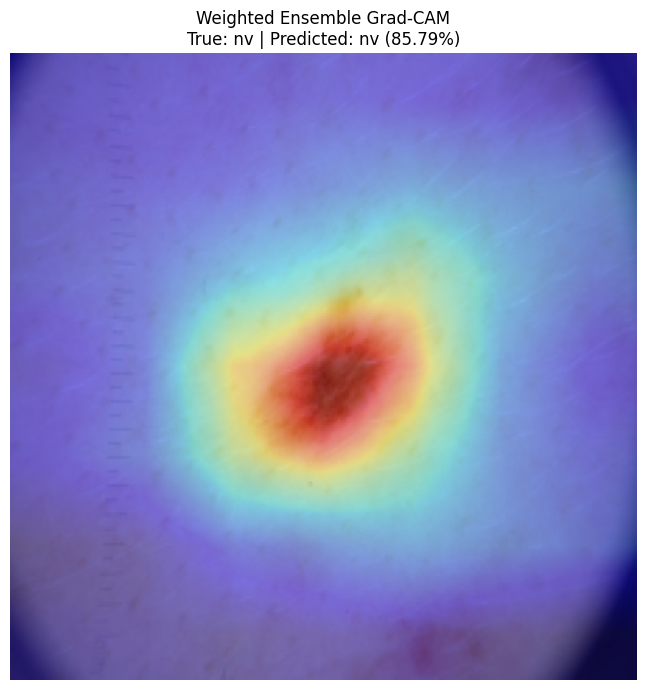

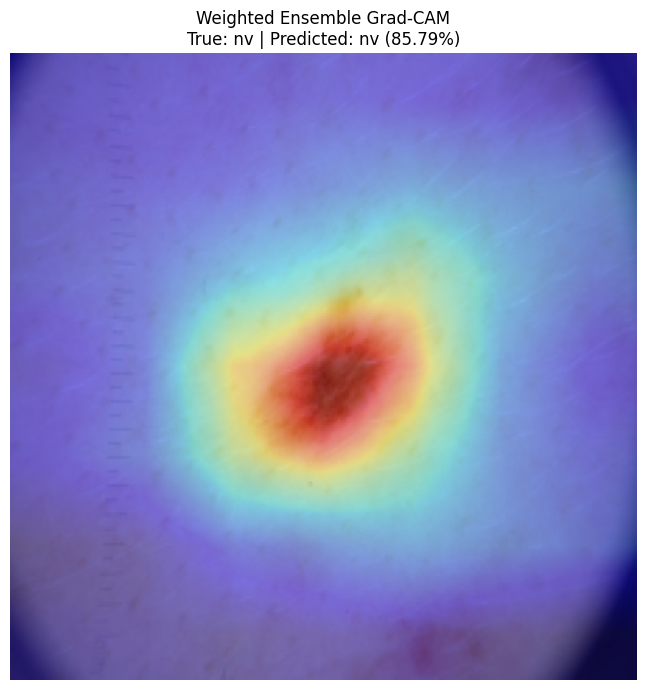

Weighted ensemble Grad-CAM saved to: /kaggle/working/ensemble_results/weighted_ensemble_gradcam.png


In [57]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# Validation-selected ensemble weights
w_resnet = 0.35
w_densenet = 0.30
w_efficientnet = 0.35

# Resize and normalize each heatmap to 224 × 224
def resize_normalize_heatmap(heatmap, size=(224, 224)):
    resized = tf.image.resize(
        heatmap[..., np.newaxis],
        size
    ).numpy().squeeze()

    resized = np.maximum(resized, 0)
    resized = resized / (resized.max() + 1e-8)

    return resized

resnet_map = resize_normalize_heatmap(
    gradcam_results["ResNet50"][0]
)

densenet_map = resize_normalize_heatmap(
    gradcam_results["DenseNet169"][0]
)

efficientnet_map = resize_normalize_heatmap(
    gradcam_results["EfficientNetB6"][0]
)

# Weighted combination of the individual Grad-CAM maps
ensemble_heatmap = (
    w_resnet * resnet_map
    + w_densenet * densenet_map
    + w_efficientnet * efficientnet_map
)

ensemble_heatmap = ensemble_heatmap / (
    ensemble_heatmap.max() + 1e-8
)

# Get the actual weighted ensemble prediction for this image
ensemble_prediction = (
    w_resnet * resnet_probs[IMAGE_INDEX]
    + w_densenet * densenet_probs[IMAGE_INDEX]
    + w_efficientnet * efficientnet_probs[IMAGE_INDEX]
)

ensemble_predicted_class = int(np.argmax(ensemble_prediction))
ensemble_confidence = float(
    ensemble_prediction[ensemble_predicted_class]
)

# Display the combined heatmap
plt.figure(figsize=(7, 7))
plt.imshow(display_image)
plt.imshow(ensemble_heatmap, cmap="jet", alpha=0.4)

plt.title(
    f"Weighted Ensemble Grad-CAM\n"
    f"True: {class_names[true_label]} | "
    f"Predicted: {class_names[ensemble_predicted_class]} "
    f"({ensemble_confidence:.2%})"
)

plt.axis("off")
plt.tight_layout()
plt.show()

# Save the combined visualization
output_dir = "/kaggle/working/ensemble_results"
os.makedirs(output_dir, exist_ok=True)

ensemble_gradcam_path = os.path.join(
    output_dir,
    "weighted_ensemble_gradcam.png"
)

plt.figure(figsize=(7, 7))
plt.imshow(display_image)
plt.imshow(ensemble_heatmap, cmap="jet", alpha=0.4)
plt.title(
    f"Weighted Ensemble Grad-CAM\n"
    f"True: {class_names[true_label]} | "
    f"Predicted: {class_names[ensemble_predicted_class]} "
    f"({ensemble_confidence:.2%})"
)
plt.axis("off")
plt.tight_layout()
plt.savefig(ensemble_gradcam_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("Weighted ensemble Grad-CAM saved to:", ensemble_gradcam_path)

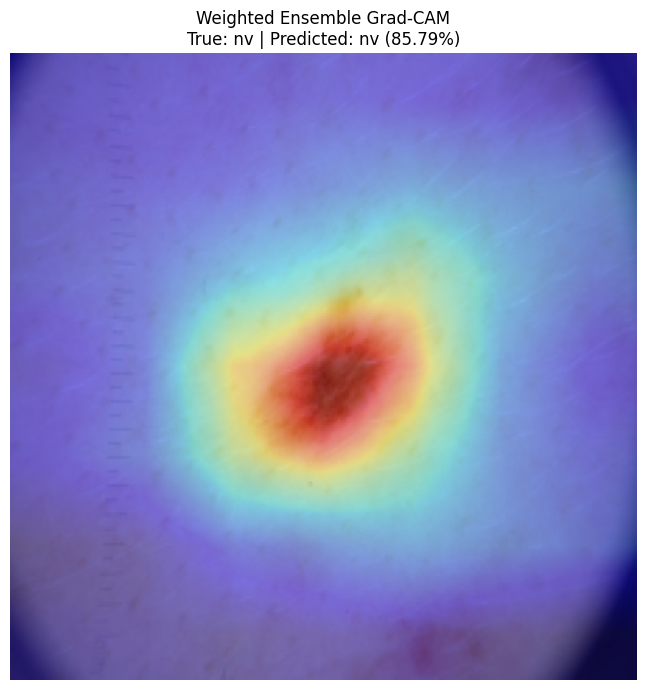

Saved: /kaggle/working/ensemble_results/weighted_ensemble_gradcam.png


In [58]:
import os
import matplotlib.pyplot as plt

output_dir = "/kaggle/working/ensemble_results"
os.makedirs(output_dir, exist_ok=True)

fig, ax = plt.subplots(figsize=(7, 7))

ax.imshow(display_image)
ax.imshow(ensemble_heatmap, cmap="jet", alpha=0.4)

ax.set_title(
    f"Weighted Ensemble Grad-CAM\n"
    f"True: {class_names[true_label]} | "
    f"Predicted: {class_names[ensemble_predicted_class]} "
    f"({ensemble_confidence:.2%})"
)

ax.axis("off")
fig.tight_layout()

ensemble_gradcam_path = os.path.join(
    output_dir, "weighted_ensemble_gradcam.png"
)

fig.savefig(
    ensemble_gradcam_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Saved:", ensemble_gradcam_path)

In [59]:
import os
import zipfile

output_dir = "/kaggle/working/ensemble_results"
zip_path = "/kaggle/working/ensemble_results.zip"

# Recreate the ZIP archive with all current result files
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk(output_dir):
        for file in files:
            file_path = os.path.join(root, file)
            arcname = os.path.relpath(file_path, output_dir)
            zipf.write(file_path, arcname)

print("Updated ZIP archive:", zip_path)
print("\nFiles included:")

with zipfile.ZipFile(zip_path, "r") as zipf:
    for name in zipf.namelist():
        print(name)

print("\nZIP archive size: {:.2f} MB".format(os.path.getsize(zip_path) / (1024 * 1024)))

Updated ZIP archive: /kaggle/working/ensemble_results.zip

Files included:
model_comparison.csv
ensemble_misclassified_images.csv
ensemble_classwise_metrics.csv
tuned_ensemble_test_predictions.csv
three_model_gradcam_comparison.png
ensemble_test_predictions.csv
final_ensemble_comparison.csv
tuned_ensemble_classification_report.txt
tuned_ensemble_config.json
equal_weight_ensemble_classification_report.txt
model_comparison_chart.png
ensemble_classwise_performance.png
densenet169_classification_report.txt
tuned_ensemble_confusion_matrix.png
efficientnetb6_classification_report.txt
weighted_ensemble_gradcam.png
resnet50_classification_report.txt
ensemble_errors_by_class.csv

ZIP archive size: 1.00 MB


In [60]:
import os
from IPython.display import FileLink, display

zip_path = "/kaggle/working/ensemble_results.zip"

if os.path.exists(zip_path):
    size_mb = os.path.getsize(zip_path) / (1024 * 1024)

    print("Ensemble results archive is ready.")
    print(f"File size: {size_mb:.2f} MB")
    print("\nClick below to download your results:")

    display(FileLink(zip_path))
else:
    print("ZIP file not found. Please run the ZIP creation cell again.")

Ensemble results archive is ready.
File size: 1.00 MB

Click below to download your results:


/kaggle/working/ensemble_results.zip

In [61]:
import os
import json
import shutil

model_dir = "/kaggle/working/ensemble_results/models"
os.makedirs(model_dir, exist_ok=True)

# Save the trained models
resnet_save_path = os.path.join(model_dir, "resnet50_ham10000.keras")
densenet_save_path = os.path.join(model_dir, "densenet169_ham10000.keras")
efficientnet_save_path = os.path.join(model_dir, "efficientnetb6_ham10000.keras")

resnet_model.save(resnet_save_path)
densenet_model.save(densenet_save_path)
efficientnet_model.save(efficientnet_save_path)

print("Models saved successfully:")
print(resnet_save_path)
print(densenet_save_path)
print(efficientnet_save_path)

# Save model configuration for backend inference
config = {
    "class_names": class_names,
    "ensemble_type": "weighted_soft_voting",
    "weights": {
        "resnet50": 0.35,
        "densenet169": 0.30,
        "efficientnetb6": 0.35
    },
    "input_sizes": {
        "resnet50": [224, 224],
        "densenet169": [224, 224],
        "efficientnetb6": [528, 528]
    },
    "preprocessing": {
        "resnet50": "Resize to 224x224; pass raw 0-255 RGB values to the model",
        "densenet169": "Resize to 224x224; apply densenet_preprocess before inference",
        "efficientnetb6": "Resize to 528x528; pass raw 0-255 RGB values to the model"
    }
}

config_path = os.path.join(model_dir, "ensemble_config.json")

with open(config_path, "w") as f:
    json.dump(config, f, indent=4)

print("Configuration saved:", config_path)

Models saved successfully:
/kaggle/working/ensemble_results/models/resnet50_ham10000.keras
/kaggle/working/ensemble_results/models/densenet169_ham10000.keras
/kaggle/working/ensemble_results/models/efficientnetb6_ham10000.keras
Configuration saved: /kaggle/working/ensemble_results/models/ensemble_config.json


In [62]:
import os
import zipfile

model_dir = "/kaggle/working/ensemble_results/models"
models_zip = "/kaggle/working/ham10000_ensemble_models.zip"

with zipfile.ZipFile(models_zip, "w", zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk(model_dir):
        for file in files:
            file_path = os.path.join(root, file)
            arcname = os.path.relpath(file_path, model_dir)
            zipf.write(file_path, arcname)

print("Model archive created:", models_zip)
print("Archive size: {:.2f} MB".format(
    os.path.getsize(models_zip) / (1024 * 1024)
))

Model archive created: /kaggle/working/ham10000_ensemble_models.zip
Archive size: 277.72 MB


In [63]:
from IPython.display import FileLink, display

display(FileLink("/kaggle/working/ham10000_ensemble_models.zip"))

/kaggle/working/ham10000_ensemble_models.zip